# 01. Signal processing

Processes Q00 recordings with C01 and C02 stored separately. `baseline` and `comparison` are analytical roles and do not confirm irradiation. Sampling frequencies in the config agree with the catalogue table at its precision (two decimals). Metadata is edited only in `src/dataset_config.py`.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

cwd = Path.cwd().resolve()
BASE_DIR = next((p for p in [cwd, *cwd.parents] if (p / "src" / "dataset_config.py").exists()), None)
if BASE_DIR is None:
    raise RuntimeError("Open this notebook from the project directory or notebooks subdirectory")
if str(BASE_DIR / "src") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "src"))
import pandas as pd
from dataset_config import DATA_DIR, DATASET_PATH, FIGURES_DIR, FILE_METADATA
print(BASE_DIR)

thin-film-noise-analysis


In [2]:
from signal_processing import (find_input_file, read_q00_file, iter_samples,
                               build_combined_dataset)
metadata = pd.DataFrame.from_dict(FILE_METADATA, orient="index")
metadata.index.name = "file"
display(metadata)

,material,material_name,experiment_id,sample_id,channel,year,sampling_rate_hz,analysis_role,used_for_training,irradiated,irradiation_date,control_mode,measurement_type
file,,,,,,,,,,,,,
BI202C01,BI,Bismuth (Bi),BI202,Bi002,C01,2005,1.731449,baseline,True,False,NaN,unknown,unknown
BI202C02,BI,Bismuth (Bi),BI202,Bi002,C02,2005,1.731449,baseline,True,False,NaN,unknown,unknown
CR202C01,CR,Chromium (Cr),CR202,Cr002,C01,2005,1.731449,baseline,True,False,NaN,unknown,unknown
CR202C02,CR,Chromium (Cr),CR202,Cr002,C02,2005,1.731449,baseline,True,False,NaN,unknown,unknown
FE202C01,FE,Iron (Fe),FE202,Fe002,C01,2005,1.731449,baseline,True,False,NaN,unregulated,unknown
FE202C02,FE,Iron (Fe),FE202,Fe002,C02,2005,1.731449,baseline,True,False,NaN,regulated,unknown
BI304C01,BI,Bismuth (Bi),BI304,Bi003,C01,2005,1.731373,baseline,True,False,NaN,unknown,unknown
BI304C02,BI,Bismuth (Bi),BI304,Bi003,C02,2005,1.731373,baseline,True,False,NaN,unknown,unknown
CR304C01,CR,Chromium (Cr),CR304,Cr003,C01,2005,1.731373,baseline,True,False,NaN,unknown,unknown


In [3]:
availability = metadata.reset_index()
availability["available"] = availability["file"].map(lambda stem: find_input_file(DATA_DIR, stem) is not None)
display(availability[["file", "experiment_id", "channel", "analysis_role", "available"]])

,file,experiment_id,channel,analysis_role,available
0,BI202C01,BI202,C01,baseline,True
1,BI202C02,BI202,C02,baseline,True
2,CR202C01,CR202,C01,baseline,True
3,CR202C02,CR202,C02,baseline,True
4,FE202C01,FE202,C01,baseline,True
5,FE202C02,FE202,C02,baseline,True
6,BI304C01,BI304,C01,baseline,True
7,BI304C02,BI304,C02,baseline,True
8,CR304C01,CR304,C01,baseline,True
9,CR304C02,CR304,C02,baseline,True


## Single example

Reads only the first record, without loading the whole file into memory. `sample_start` is the index of a point within the record, not absolute time.

In [4]:
available = availability.loc[availability["available"], "file"]
if available.empty:
    raise FileNotFoundError("No registered Q00 files found")
example_stem = "BI202C01" if "BI202C01" in set(available) else available.iloc[0]
reader = read_q00_file(find_input_file(DATA_DIR, example_stem))
try:
    record = next(reader)
finally:
    reader.close()
print(example_stem, {key: value for key, value in record.items() if key != "codes"})
print("Points:", len(record["codes"]))
first_window = next(iter_samples(record["codes"]), None)
print("First window start / length:", None if first_window is None else (first_window[0], len(first_window[1])))

BI202C01 {'km': 0.06960000097751617, 'ku': 67.19999694824219, 'jd1': 2453597.889652778, 'jd2': 2453597.9444212965, 'up1': 12.630000114440918, 'up2': 12.623187065124512, 'kc': 204800}
Points: 8192
First window start / length: (0, 128)


## Build or load

Set `REBUILD = True` after changing metadata or parameters. Processing large files can take a while.

In [5]:
REBUILD = False
if REBUILD or not DATASET_PATH.exists():
    df = build_combined_dataset()
else:
    df = pd.read_csv(DATASET_PATH)
required = {"material", "channel", "experiment_id", "analysis_role", "control_mode",
            "measurement_type", "electrode_distance_mm", "record_index", "sample_start"}
if required - set(df.columns):
    raise ValueError("Old CSV: set REBUILD=True and rerun this cell")
display(df.head())

,gamma,energy,jd1,jd2,record_index,sample_start,file,material,material_name,experiment_id,...,sampling_rate_hz,analysis_role,used_for_training,irradiated,control_mode,measurement_type,sample_length,overlap_mode,log_energy,electrode_distance_mm
0,0.398660,1.571536e-09,2.453598e+06,2.453598e+06,1,0,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,NaN,unknown,unknown,128,2,-8.803676,NaN
1,-0.175839,3.100287e-09,2.453598e+06,2.453598e+06,1,64,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,NaN,unknown,unknown,128,2,-8.508598,NaN
2,-0.094906,1.338760e-09,2.453598e+06,2.453598e+06,1,128,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,NaN,unknown,unknown,128,2,-8.873297,NaN
3,-0.136083,1.224634e-09,2.453598e+06,2.453598e+06,1,192,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,NaN,unknown,unknown,128,2,-8.911994,NaN
4,-0.094538,1.233776e-09,2.453598e+06,2.453598e+06,1,256,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,NaN,unknown,unknown,128,2,-8.908764,NaN


In [6]:
display(df.groupby(["material", "experiment_id", "channel"]).size().rename("n_windows").to_frame())
display(df.groupby(["material", "experiment_id", "channel"])[["gamma", "log_energy"]].agg(["count", "mean", "std"]))

n_windows
material experiment_id channel           
AL       AL103         C01          42651
                       C02          42651
BI       BI105         C01          66900
                       C02          66900
         BI106         C01         143237
                       C02         143237
         BI202         C01          32187
                       C02          32187
         BI304         C01          94551
                       C02          94551
CO       CO105         C01          84819
                       C02          84819
         COB01         C01          30240
                       C02          30240
                       C03          30240
CR       CR202         C01          32187
                       C02          32187
         CR205         C01          66900
                       C02          66900
         CR206         C01         143237
                       C02         143237
         CR304         C01          94551
                       C02          94551
FE       FE104         C01          94551
                       C02          94551
         FE105         C01          66900
                       C02          66900
         FE106         C01         143237
                       C02         143237
         FE202         C01          32187
                       C02          32187
XXX      XXX01         C01          44998
                       C02          44998
                       C03          44998
                       C04          44998
                       C05          44998
                       C06          44998

gamma                     log_energy  \
                                 count      mean       std      count   
material experiment_id channel                                          
AL       AL103         C01       42651 -0.092540  0.271783      42651   
                       C02       42651  0.058714  0.273262      42651   
BI       BI105         C01       66900 -0.568314  0.390099      66900   
                       C02       66900 -0.692336  0.534009      66900   
         BI106         C01      143237 -0.241357  0.268624     143237   
                       C02      143237 -0.366708  0.267364     143237   
         BI202         C01       32187 -0.470109  0.540253      32187   
                       C02       32187 -0.478716  0.503550      32187   
         BI304         C01       94551 -0.124249  0.290938      94551   
                       C02       94551 -0.532466  0.698097      94551   
CO       CO105         C01       84819 -0.068229  0.384906      84819   
                       C02       84819 -0.176547  0.574999      84819   
         COB01         C01       30240 -0.022885  0.283847      30240   
                       C02       30240  0.031107  0.344440      30240   
                       C03       30240  0.118224  0.420049      30240   
CR       CR202         C01       32187 -1.142927  0.334512      32187   
                       C02       32187 -1.213332  0.364768      32187   
         CR205         C01       66900 -1.343322  0.416104      66900   
                       C02       66900 -1.614374  0.441017      66900   
         CR206         C01      143237 -1.152569  0.322257     143237   
                       C02      143237 -1.257296  0.400625     143237   
         CR304         C01       94551 -0.045314  0.253824      94551   
                       C02       94551 -0.119346  0.264892      94551   
FE       FE104         C01       94551 -0.100087  0.335642      94551   
                       C02       94551 -0.246476  0.383207      94551   
         FE105         C01       66900 -0.032205  0.252100      66900   
                       C02       66900 -0.054057  0.260192      66900   
         FE106         C01      143237  0.001359  0.250152     143237   
                       C02      143237 -0.001088  0.250566     143237   
         FE202         C01       32187 -0.471432  0.293924      32187   
                       C02       32187 -0.644830  0.302899      32187   
XXX      XXX01         C01       44998 -0.035508  0.278235      44998   
                       C02       44998 -0.007037  0.285060      44998   
                       C03       44998 -0.146905  0.276700      44998   
                       C04       44998 -0.158153  0.296683      44998   
                       C05       44998 -0.168758  0.278089      44998   
                       C06       44998 -0.692106  0.610180      44998   

                                                      
                                     mean        std  
material experiment_id channel                        
AL       AL103         C01      -9.073048   0.466825  
                       C02      -8.832340   0.378590  
BI       BI105         C01      -8.699880   0.309932  
                       C02     -12.108584   8.475529  
         BI106         C01      -8.695099   0.193138  
                       C02      -8.950260   0.156747  
         BI202         C01      -6.829966   3.273696  
                       C02      -8.929740   0.834906  
         BI304         C01      -8.609830   0.218347  
                       C02     -13.295722   9.765186  
CO       CO105         C01      -7.552077   4.037379  
                       C02      -9.263477   6.823738  
         COB01         C01      -8.995332   0.522114  
                       C02      -6.796718   0.376144  
                       C03      -7.089242   0.602198  
CR       CR202         C01      -8.099813   0.355083  
                       C02      -9.847203   6.446889  
         CR2

## Plots

These use the same functions as `train_models.py`. Running this cell overwrites the four feature figures in `results/figures`. Panels have independent y-axis scales. Error bars show the standard deviation across windows, not a confidence interval.

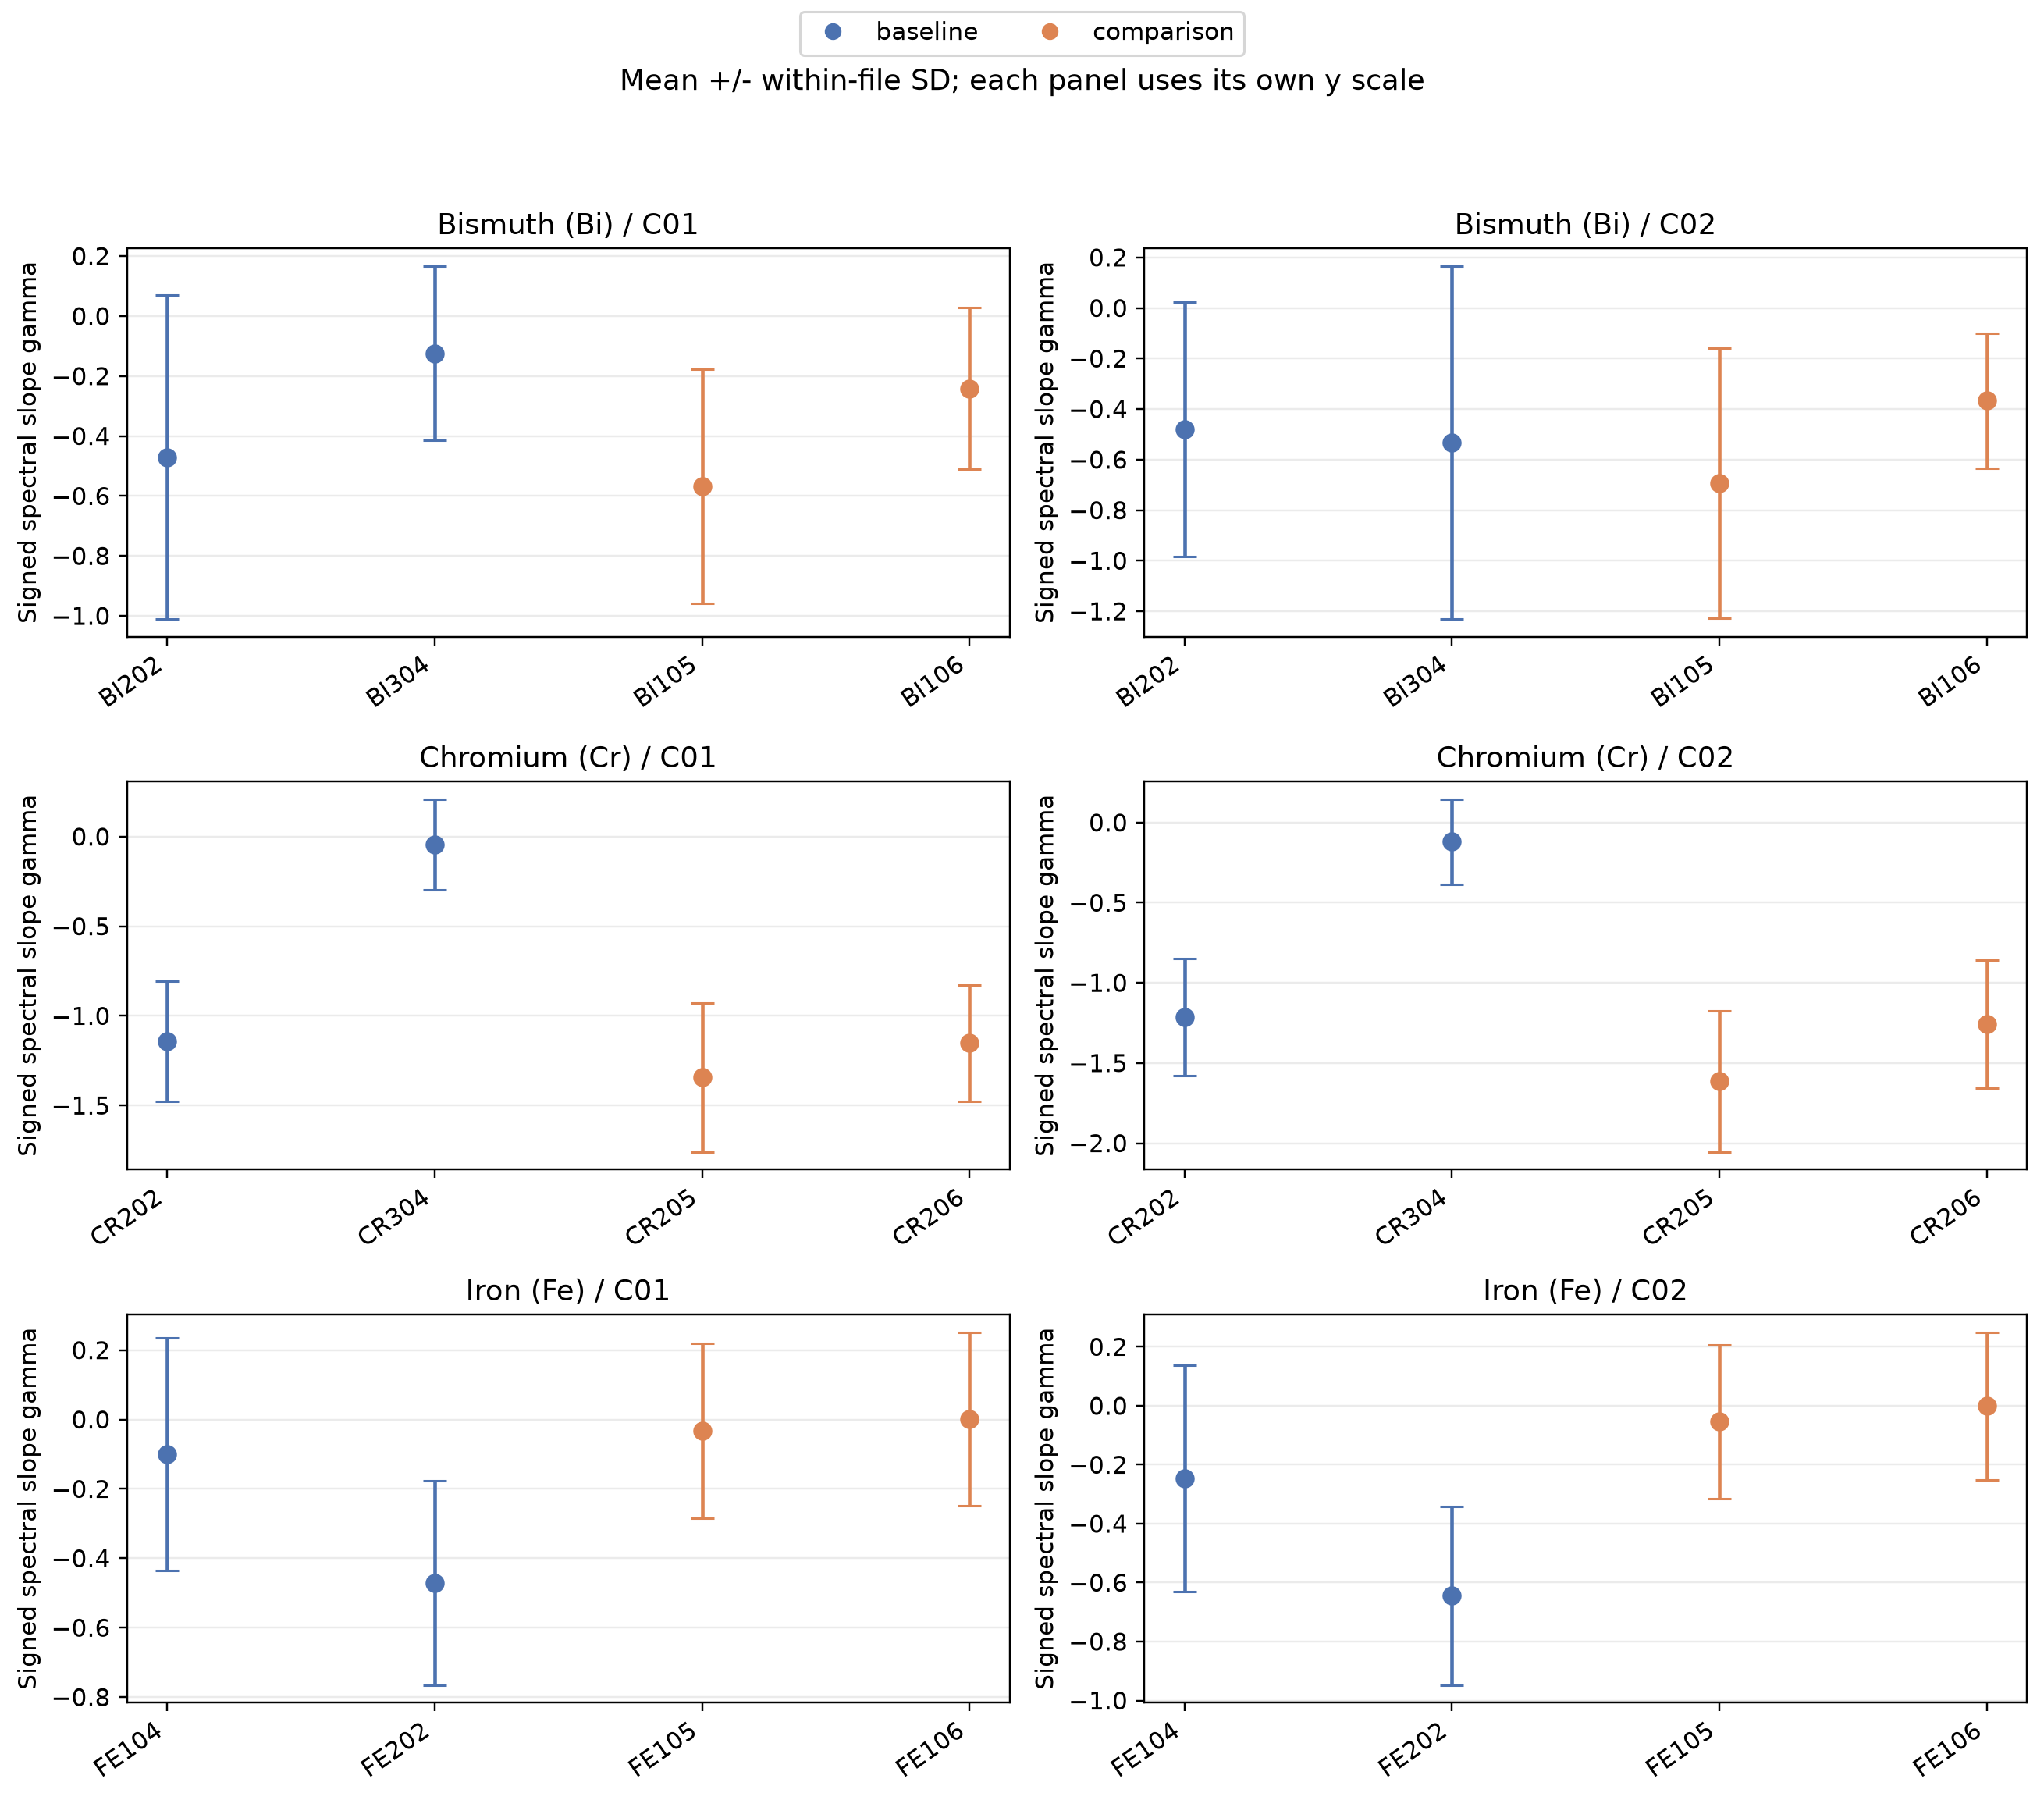

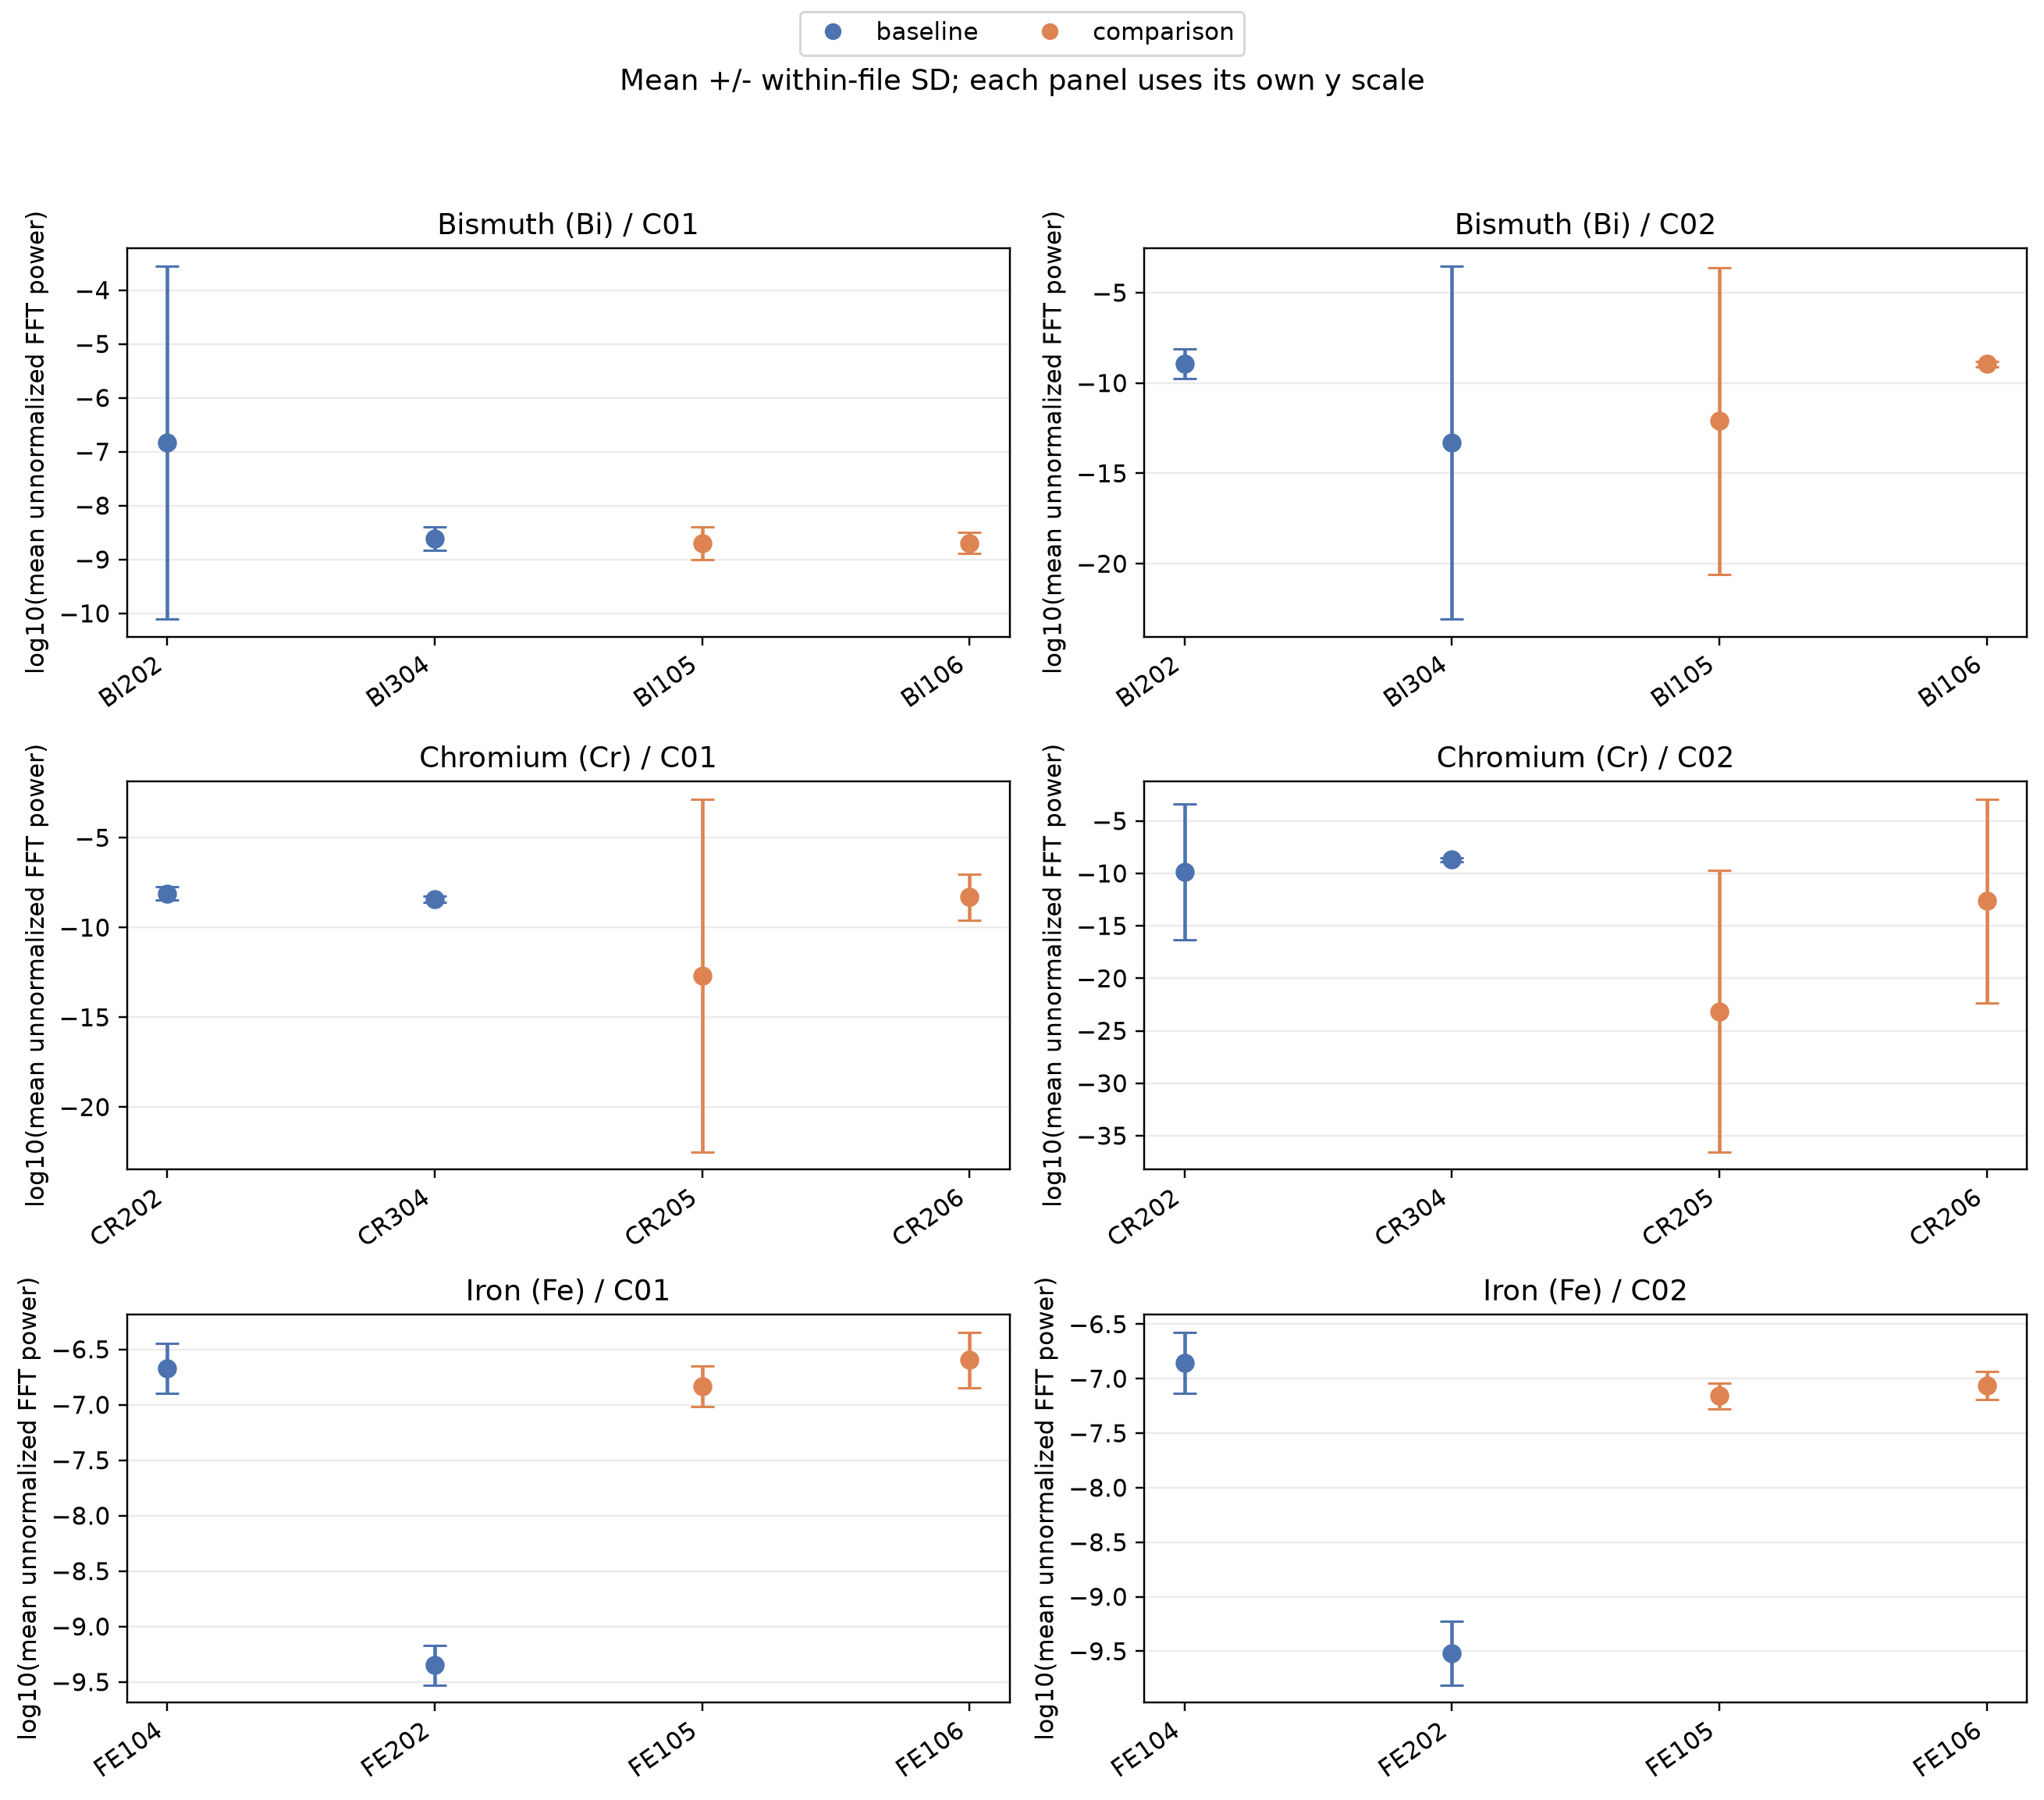

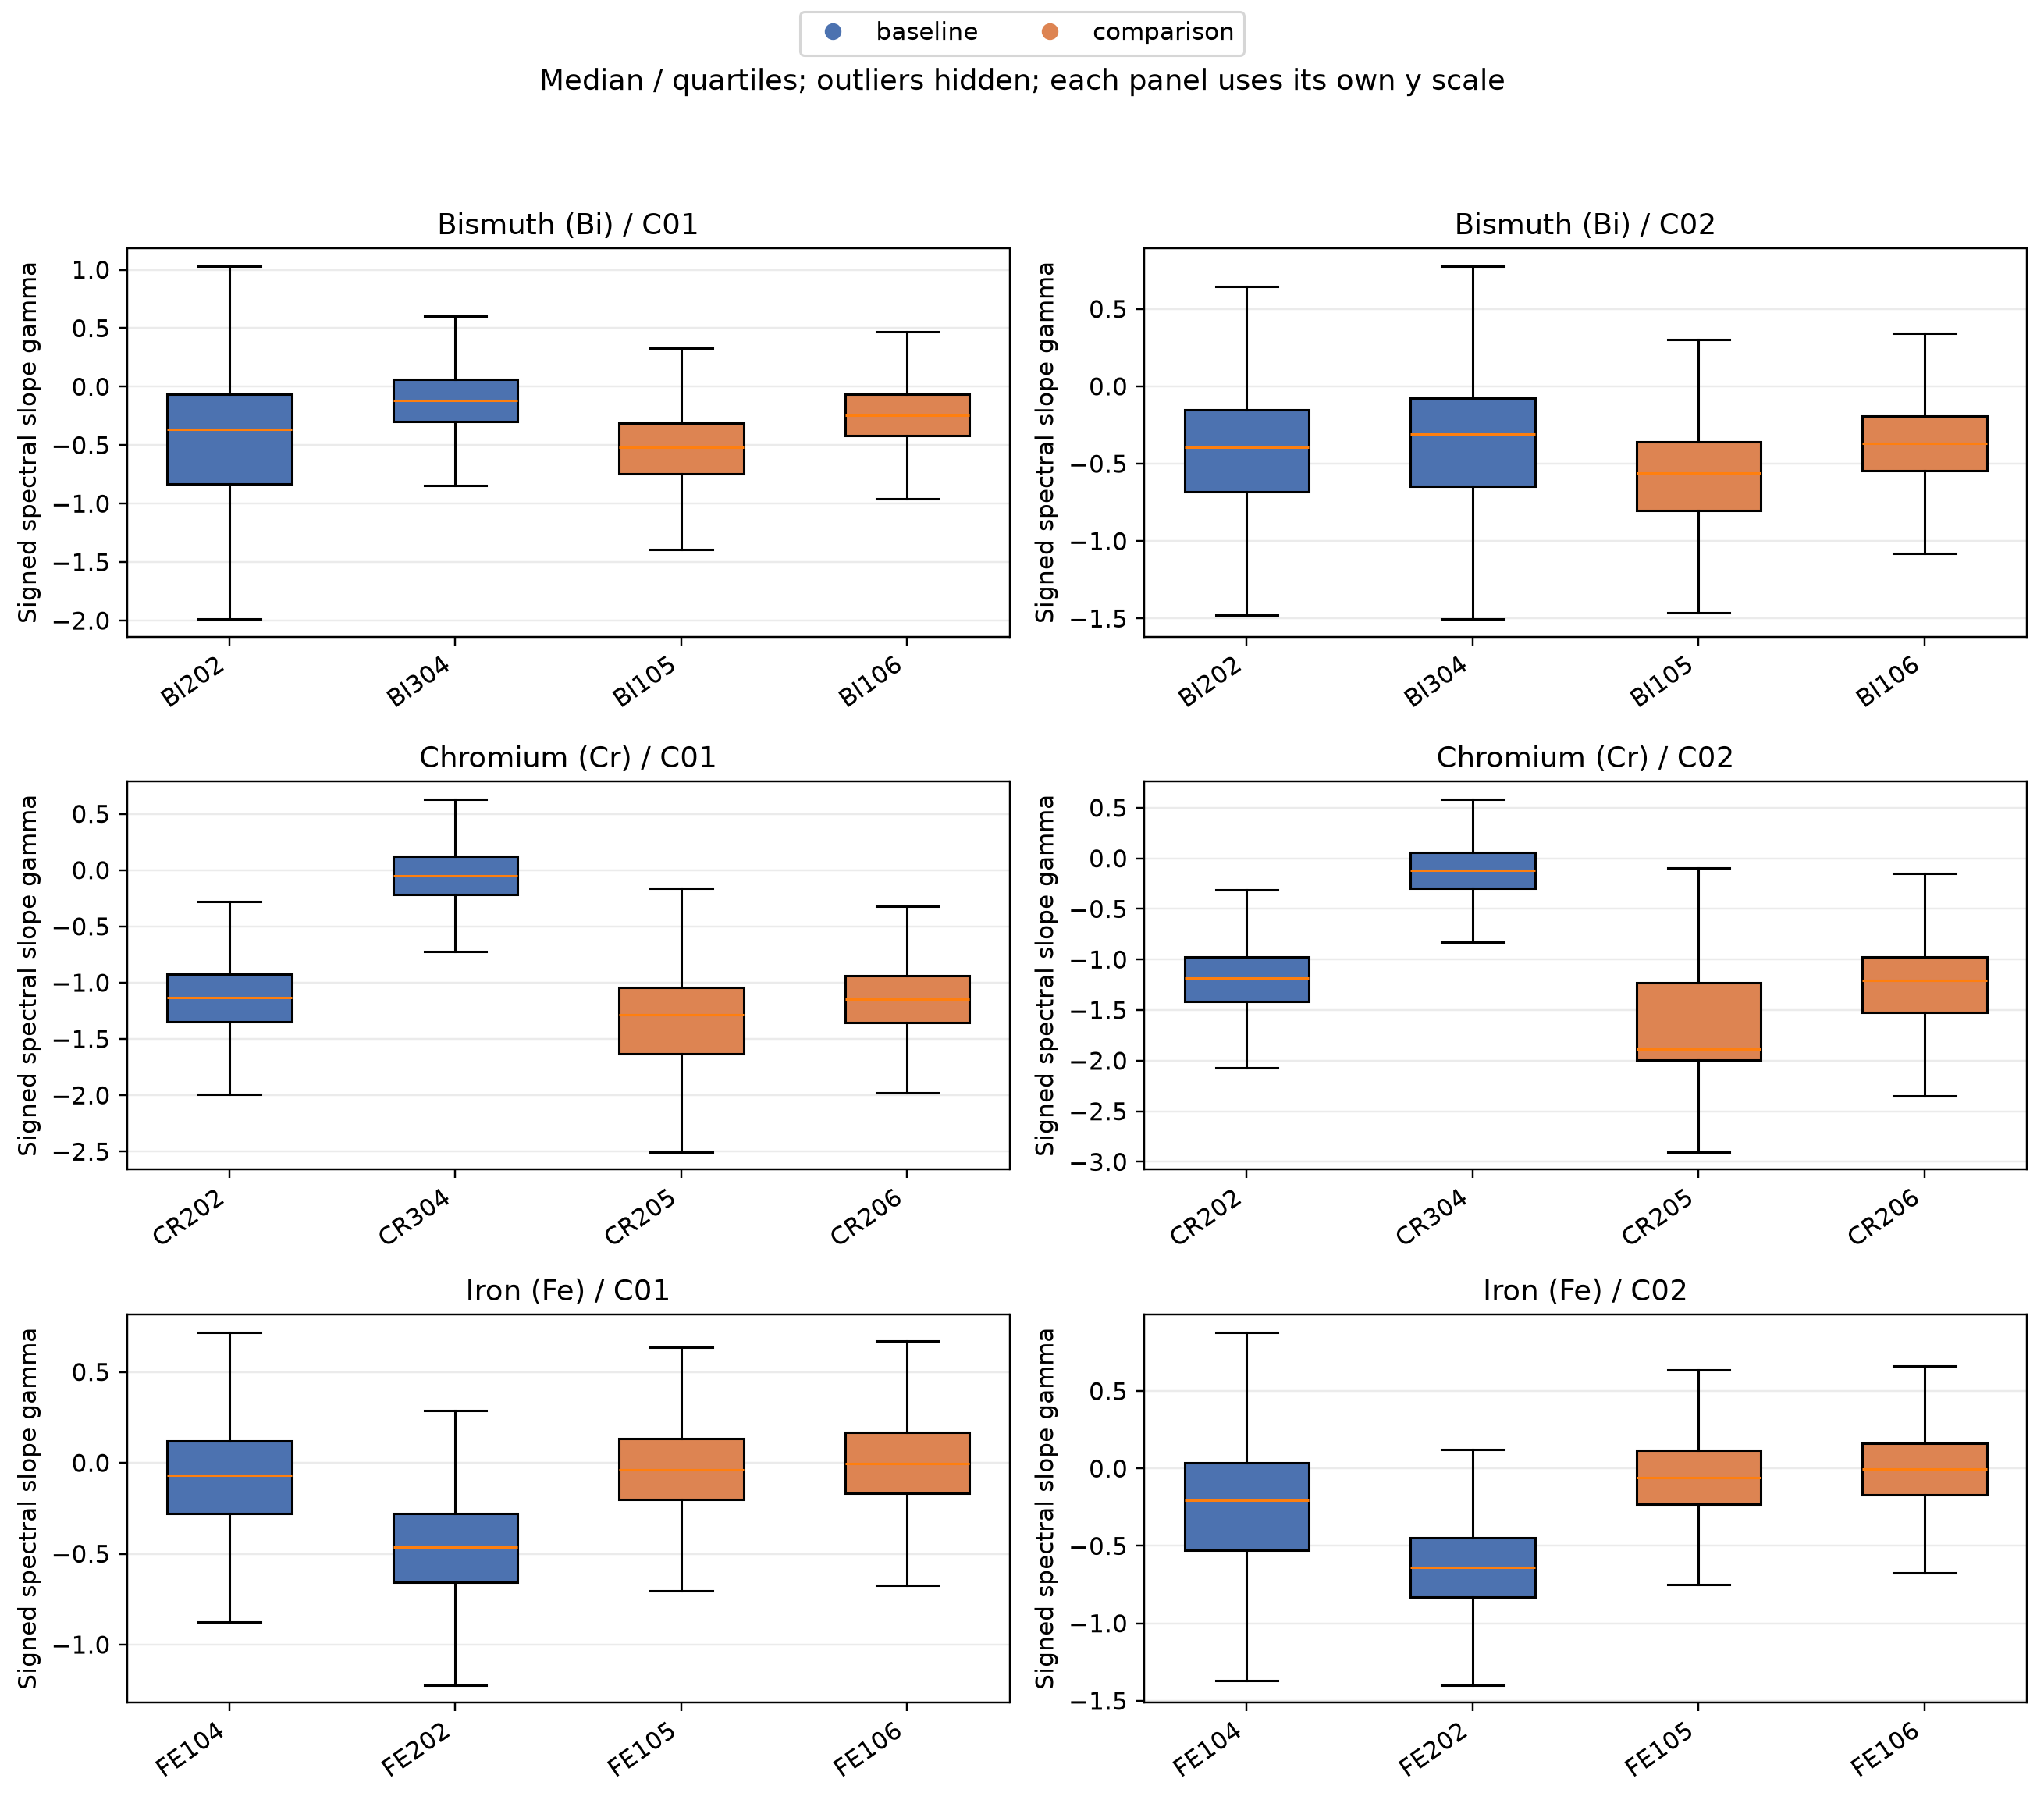

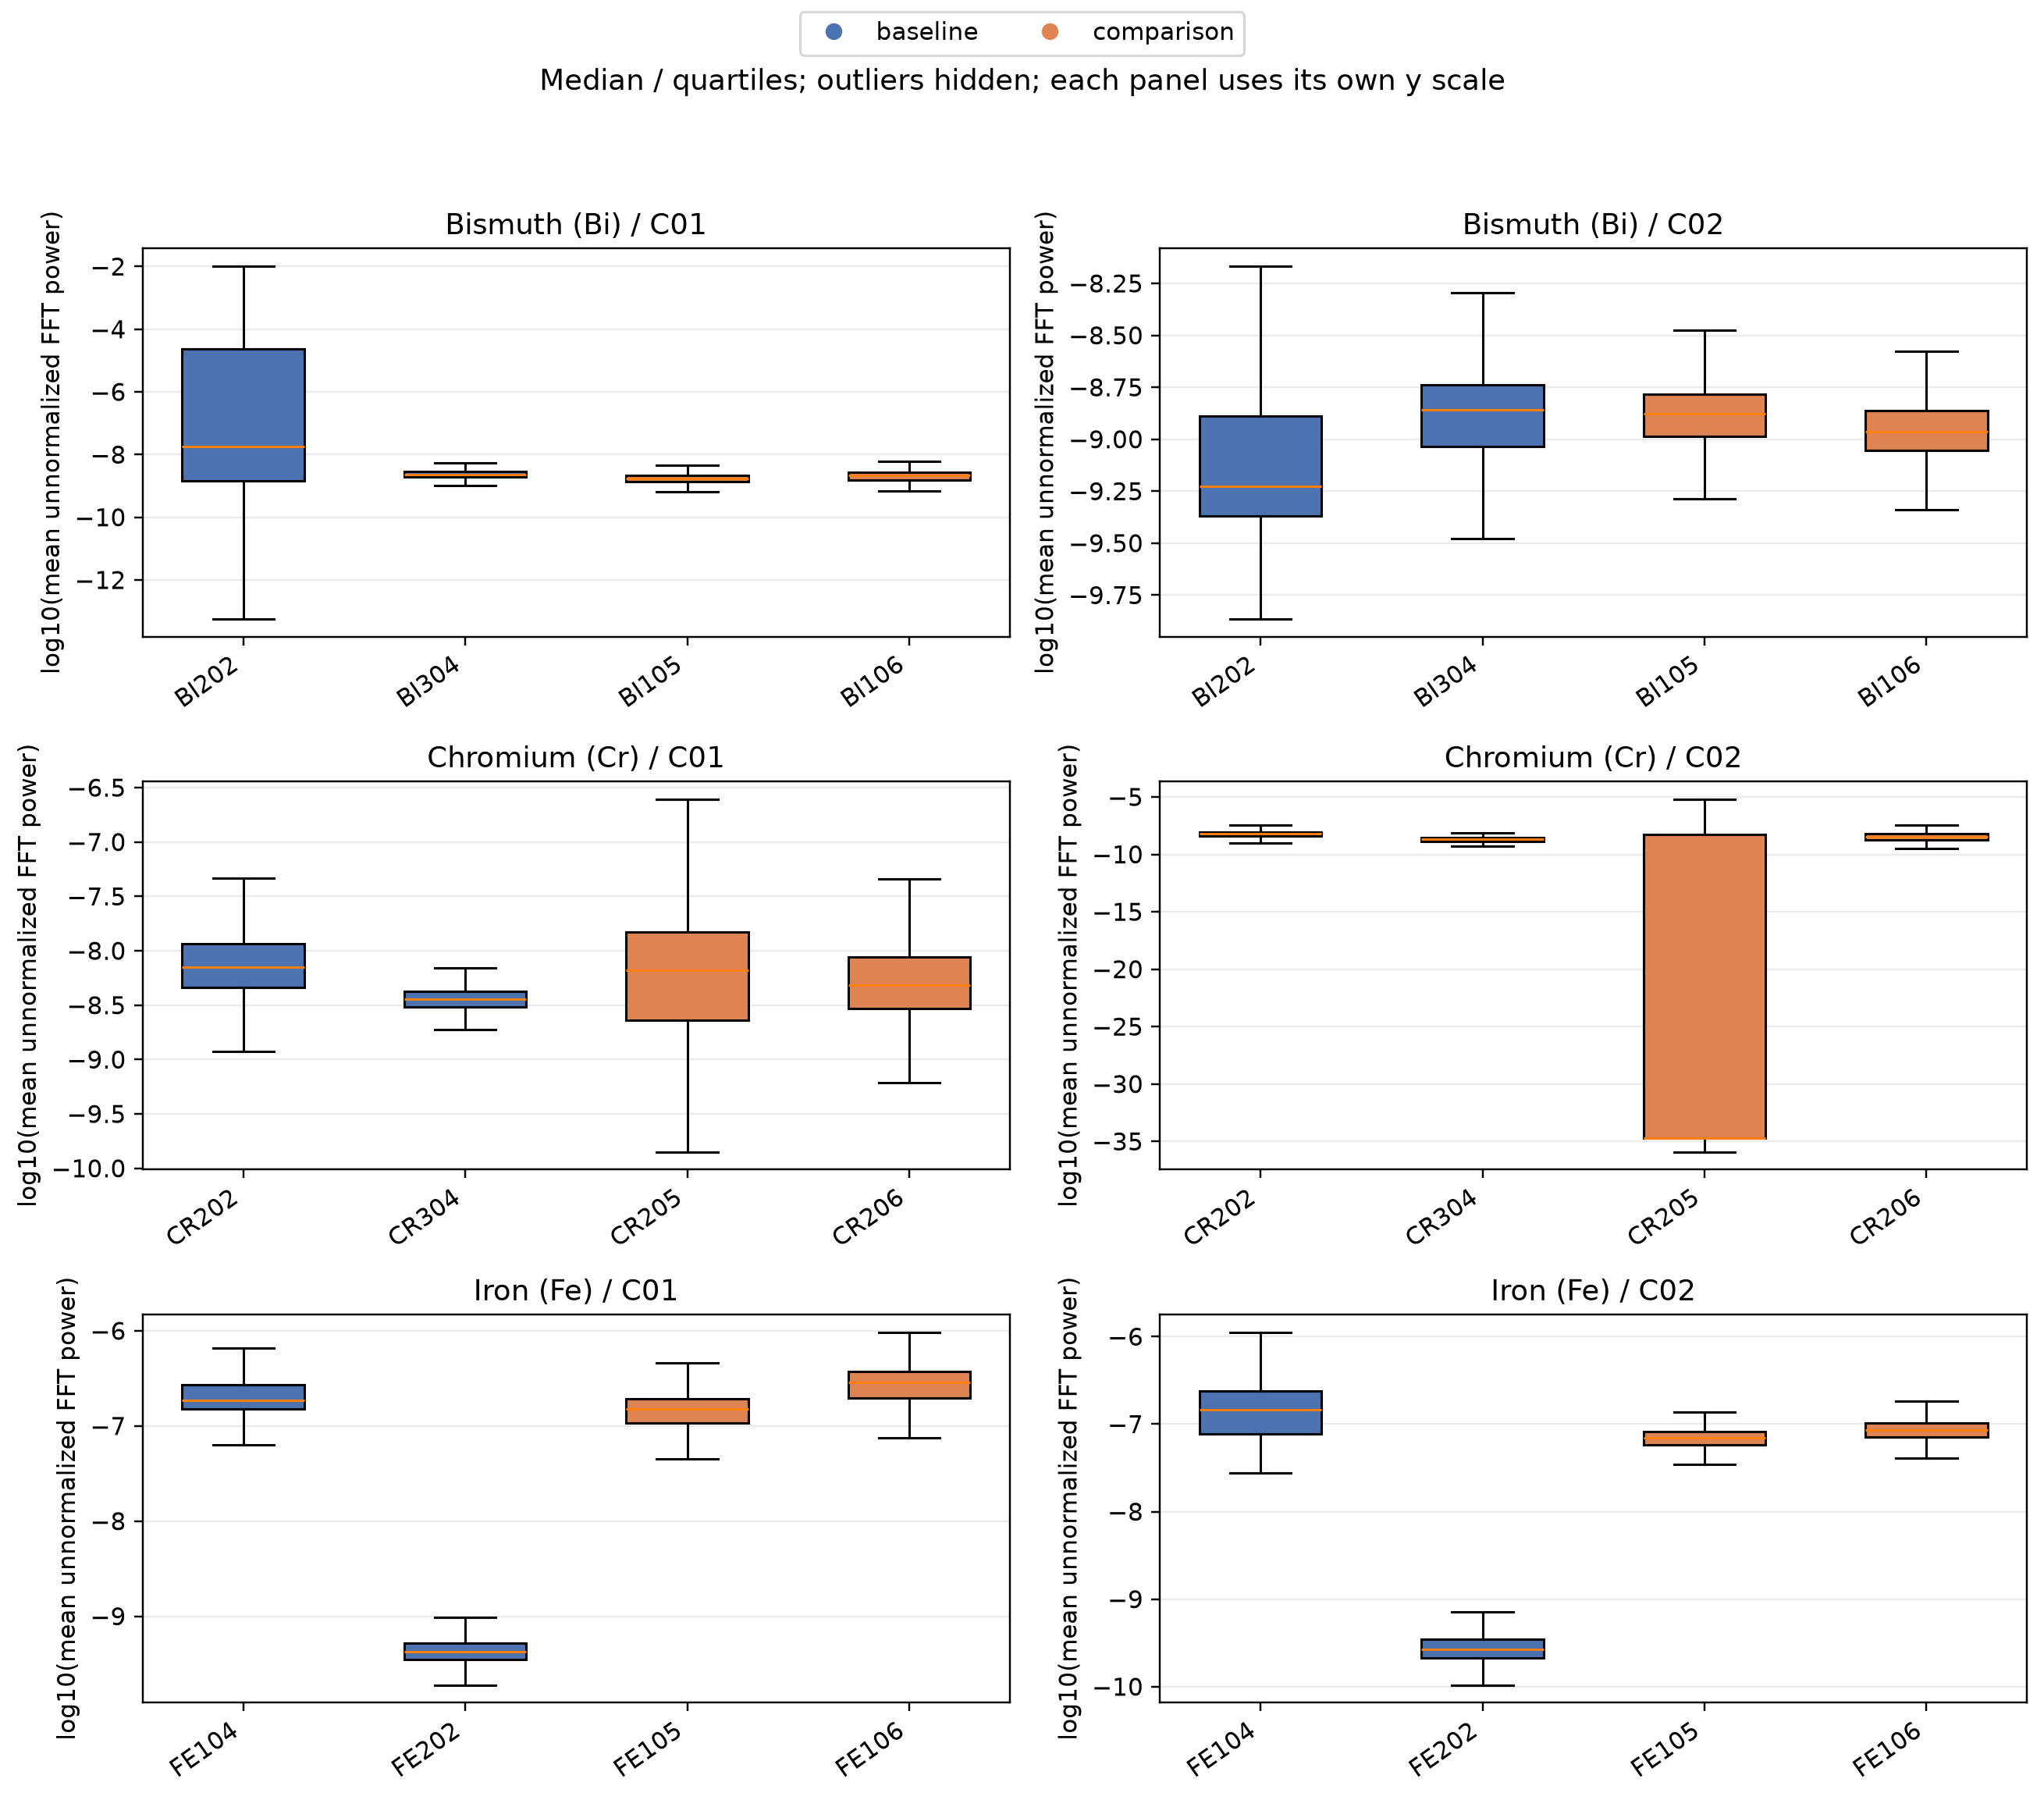

In [7]:
from train_models import load_dataset, save_feature_plots
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
clean_df = load_dataset()
save_feature_plots(clean_df)
for filename in ("file_level_gamma_comparison.png", "file_level_energy_comparison.png",
                 "gamma_boxplots_by_file.png", "energy_boxplots_by_file.png"):
    if (FIGURES_DIR / filename).exists():
        display(Image(filename=str(FIGURES_DIR / filename)))

## Limitations

`gamma` is a signed slope. `energy` is the mean of the unnormalized squared FFT magnitude, not a PSD. Changing the frequency without changing the frequency indices used does not correct the slope. Reference channels and exploratory series are registered but not used for training automatically. For COB01, electrode distance is labelled only for C03, according to the provided description.